# Reconstruct the energy and recycle calculation

**Question:** At a common calibration point, how do Bond, Rittinger and Kick diverge as target size changes?

Level: 2. Prerequisites: Level 1: Follow a copper ore through crushing and grinding. Reading time: 28 minutes.

## Objectives

Reproduce a nominal circuit run from OreFlow's declared case, inspect the classifier and energy stages, and test how the implemented Bond law responds to a controlled P80 change. Every computed quantity comes from the pipeline methods.

## Setup

```bash
pip install numpy==2.2.6 scipy==1.17.1 pandas==2.2.3 matplotlib==3.11.2 nbclient==0.11.0 nbformat==5.11.1 ipykernel==7.4.0 SALib==1.6.0
```

The OreFlow pipeline is imported from `data-pipeline/`; this notebook never installs packages.

For the level 2 01-comminution lesson, record the pinned versions before analysis so the environment behind its tables and figures can be reconstructed.

In [1]:
# Import analysis tools and record their exact versions.
import importlib.metadata
import json
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Resolve the local pipeline from the repository-relative layout.
repo = Path("../../../").resolve()
sys.path.insert(0, str(repo / "data-pipeline"))
for package in ("numpy", "scipy", "pandas", "matplotlib", "nbclient", "nbformat", "ipykernel"):
    print(package, importlib.metadata.version(package))


numpy 2.2.6
scipy 1.17.1
pandas 2.2.3
matplotlib 3.11.2
nbclient 0.11.0
nbformat 5.11.1
ipykernel 7.4.0


## Data

Owner: OreFlow project authors; authored soft-copper-porphyry circuit, MIT project licence, `data/derived/cases/copper_porphyry_soft.json`. Operating bounds are declared in `data/derived/contract/operating_contract.json`. HZDR particle records are a separate constructed research source, not plant observations; their summary is `data/derived/source/hzdr_particle_benchmark.json`. Repository: https://github.com/fsantibanezleal/CAOS_OreFlow.

## Method

Bond's standard-circuit requirement is $W_B=W_i(10/\sqrt{P_{80}}-10/\sqrt{F_{80}})$ in kWh/t (GMG01-MP-2021, Eq. 3). OreFlow reports its net grinding energy separately. The classifier acts on every size class and solves the recycle loop; the underflow is not fresh throughput. The `energy_report` and `law_curves` functions are pipeline implementations, not notebook copies.

Run the production engine again so this lesson is independently executable. Inspect the actual solved power, classifier cut, recycle load and fineness.

In [2]:
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate

# Solve the authored case with its declared nominal controls.
case = next(item for item in CASES if item.id == "copper_porphyry_soft")
result = simulate(case.ore, case.plant, case.nominal)
grind = result.grinding
print("mill power (kW):", round(grind.power_kw, 1))
print("required power (kW):", round(grind.required_power_kw, 1))
print("classifier cut (µm):", round(grind.cut_um, 1))
print("circulating load (%):", round(100 * grind.circulating_load, 1))
print("power limited:", grind.power_limited)


mill power (kW): 6456.5
required power (kW): 6456.5
classifier cut (µm): 183.9
circulating load (%): 250.0
power limited: False


Inspect selected size-class partition values. A classifier partition is the fraction of a size class sent to underflow; it is not the fraction of the total stream recycled.

,size_um,underflow_share
0,137550.606481,NaN
1,34387.651620,NaN
2,7229.113244,1.000000
3,1519.733853,1.000000
4,319.484687,0.912833
5,67.163382,0.347523
6,14.119362,0.287011
7,2.968230,0.284220


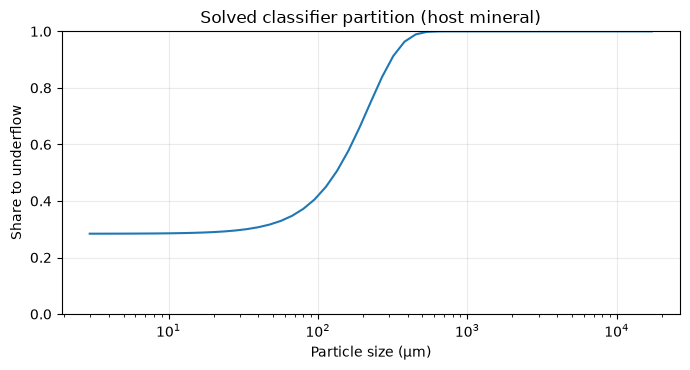

In [3]:
# Show selected rows from OreFlow's solved per-class partition.
size = np.asarray(result.curves["size_um"])
partition = np.asarray([v if v is not None else np.nan for v in grind.partition["host"]])
selected = np.linspace(0, len(size) - 1, 8, dtype=int)
display(pd.DataFrame({"size_um": size[selected], "underflow_share": partition[selected]}))
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(size, partition)
ax.set_xscale("log")
ax.set_ylim(0, 1)
ax.set(
    xlabel="Particle size (µm)",
    ylabel="Share to underflow",
    title="Solved classifier partition (host mineral)",
)
ax.grid(True, alpha=0.25)
fig.tight_layout()


Figure 11 in the level 2 01 comminution lesson reports outputs of independently solved operating points. For figure 11 in level 2 01 comminution, each mark is a separate model evaluation at its stated setting. For figure 11 in level 2 01 comminution, check recovery, size and energy against the contract limits. The line in figure 11 only guides comparison.

Call OreFlow's energy reporting function using the solved F80/P80 and charge energy. The report keeps the Bond requirement and the alternative comparison laws as separate quantities.

In [4]:
from pipeline.engine.energy import energy_report

# Use the engine's own report function; do not sum alternative laws.
energy = energy_report(
    case.nominal.work_index_kwh_t,
    case.ore.crushing_work_index_kwh_t,
    result.metrics["crusher_feed_f80_um"],
    result.metrics["crusher_p80_um"],
    grind.specific_energy_kwh_t,
    grind.feed_f80_um,
    grind.p80_um,
)
display(pd.Series(energy, name="kWh/t or dimensionless").to_frame())


,kWh/t or dimensionless
specific_energy_crushing_kwh_t,0.825221
specific_energy_grinding_kwh_t,8.967354
specific_energy_total_kwh_t,9.792575
bond_energy_kwh_t,7.782543
operating_work_index_kwh_t,12.674635
bond_efficiency_ratio,0.867875
energy_rittinger_kwh_t,7.858905
energy_kick_kwh_t,7.558261


Sweep only the product size in the published Bond equation, while leaving the ore work index and feed F80 fixed. This is a sensitivity calculation using OreFlow's implemented function, not a new plant optimization.

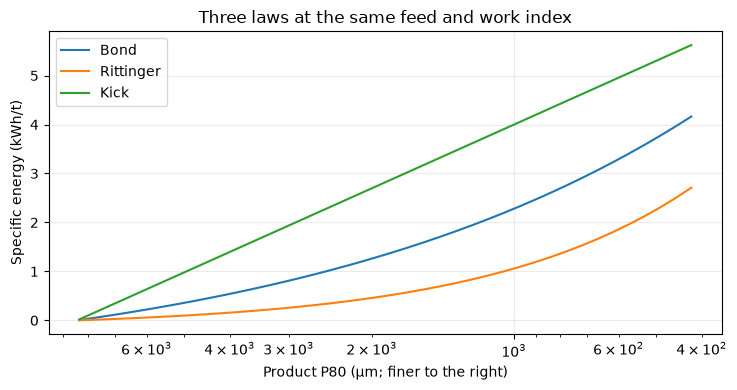

In [5]:
from pipeline.engine.energy import law_curves

# Reuse OreFlow's comparison-law implementation over a controlled P80 range.
f80 = max(grind.feed_f80_um, 2 * grind.p80_um)
p80_values = np.geomspace(max(70, f80 / 20), f80 / 1.01, 40)
laws = law_curves(case.nominal.work_index_kwh_t, f80, p80_values)
fig, ax = plt.subplots(figsize=(7.5, 4))
for name in ("bond", "rittinger", "kick"):
    ax.plot(laws["p80_um"], laws[name], label=name.title())
ax.set_xscale("log")
ax.invert_xaxis()
ax.set(
    xlabel="Product P80 (µm; finer to the right)",
    ylabel="Specific energy (kWh/t)",
    title="Three laws at the same feed and work index",
)
ax.grid(True, alpha=0.25)
ax.legend()
fig.tight_layout()


Figure 15 in the level 2 01 comminution lesson reports outputs of independently solved operating points. For figure 15 in level 2 01 comminution, each mark is a separate model evaluation at its stated setting. For figure 15 in level 2 01 comminution, check recovery, size and energy against the contract limits. The line in figure 15 only guides comparison.

In the level 2 01 comminution case, the 0.8× nominal throughput run changes fresh-feed rate while holding the other controls at their authored nominal point. For the level 2 01 comminution case at 0.8× feed, recovery, product size and energy are coupled outputs of the resolved circuit model.

In [6]:
# Re-solve the production circuit at one controlled throughput multiplier.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate

case = next(item for item in CASES if item.id == "copper_porphyry_soft")
factor = 0.8
point_0_8 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor)
response_0_8 = simulate(case.ore, case.plant, point_0_8)
print("throughput (t/h):", round(point_0_8.throughput_tph, 2))
print("recovery (%):", round(response_0_8.metrics["recovery_pct"], 3))
print("product P80 (µm):", round(response_0_8.metrics["p80_um"], 2))


throughput (t/h): 576.0
recovery (%): 93.788
product P80 (µm): 150.0


In the level 2 01 comminution case, the 0.9× nominal throughput run changes fresh-feed rate while holding the other controls at their authored nominal point. For the level 2 01 comminution case at 0.9× feed, recovery, product size and energy are coupled outputs of the resolved circuit model.

In [7]:
# Re-solve the production circuit at one controlled throughput multiplier.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate

case = next(item for item in CASES if item.id == "copper_porphyry_soft")
factor = 0.9
point_0_9 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor)
response_0_9 = simulate(case.ore, case.plant, point_0_9)
print("throughput (t/h):", round(point_0_9.throughput_tph, 2))
print("recovery (%):", round(response_0_9.metrics["recovery_pct"], 3))
print("product P80 (µm):", round(response_0_9.metrics["p80_um"], 2))


throughput (t/h): 648.0
recovery (%): 92.996
product P80 (µm): 150.0


In the level 2 01 comminution case, the 1.0× nominal throughput run changes fresh-feed rate while holding the other controls at their authored nominal point. For the level 2 01 comminution case at 1.0× feed, recovery, product size and energy are coupled outputs of the resolved circuit model.

In [8]:
# Re-solve the production circuit at one controlled throughput multiplier.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate

case = next(item for item in CASES if item.id == "copper_porphyry_soft")
factor = 1.0
point_1_0 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor)
response_1_0 = simulate(case.ore, case.plant, point_1_0)
print("throughput (t/h):", round(point_1_0.throughput_tph, 2))
print("recovery (%):", round(response_1_0.metrics["recovery_pct"], 3))
print("product P80 (µm):", round(response_1_0.metrics["p80_um"], 2))


throughput (t/h): 720.0
recovery (%): 92.213
product P80 (µm): 150.0


In the level 2 01 comminution case, the 1.1× nominal throughput run changes fresh-feed rate while holding the other controls at their authored nominal point. For the level 2 01 comminution case at 1.1× feed, recovery, product size and energy are coupled outputs of the resolved circuit model.

In [9]:
# Re-solve the production circuit at one controlled throughput multiplier.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate

case = next(item for item in CASES if item.id == "copper_porphyry_soft")
factor = 1.1
point_1_1 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor)
response_1_1 = simulate(case.ore, case.plant, point_1_1)
print("throughput (t/h):", round(point_1_1.throughput_tph, 2))
print("recovery (%):", round(response_1_1.metrics["recovery_pct"], 3))
print("product P80 (µm):", round(response_1_1.metrics["p80_um"], 2))


throughput (t/h): 792.0
recovery (%): 91.437
product P80 (µm): 150.0


In the level 2 01 comminution case, the 1.2× nominal throughput run changes fresh-feed rate while holding the other controls at their authored nominal point. For the level 2 01 comminution case at 1.2× feed, recovery, product size and energy are coupled outputs of the resolved circuit model.

In [10]:
# Re-solve the production circuit at one controlled throughput multiplier.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate

case = next(item for item in CASES if item.id == "copper_porphyry_soft")
factor = 1.2
point_1_2 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor)
response_1_2 = simulate(case.ore, case.plant, point_1_2)
print("throughput (t/h):", round(point_1_2.throughput_tph, 2))
print("recovery (%):", round(response_1_2.metrics["recovery_pct"], 3))
print("product P80 (µm):", round(response_1_2.metrics["p80_um"], 2))


throughput (t/h): 864.0
recovery (%): 88.442
product P80 (µm): 165.93


In the level 2 01 comminution lesson, plot reading 1 considers in this level 2 01 comminution plot, compare recovery with product P80 across the controlled throughput changes. In the level 2 01 comminution lesson, plot reading 2 considers the two axes keep unlike units separate, so interpret each change as a response of this authored case rather than as an empirical plant trend. In the level 2 01 comminution lesson, plot reading 3 considers the nominal point is included as a reference for the neighboring settings. In the level 2 01 comminution lesson, plot reading 4 considers for reconstruct the energy and recycle calculation, the plotted points come from separate engine evaluations, and the lines only guide the eye between tested settings.

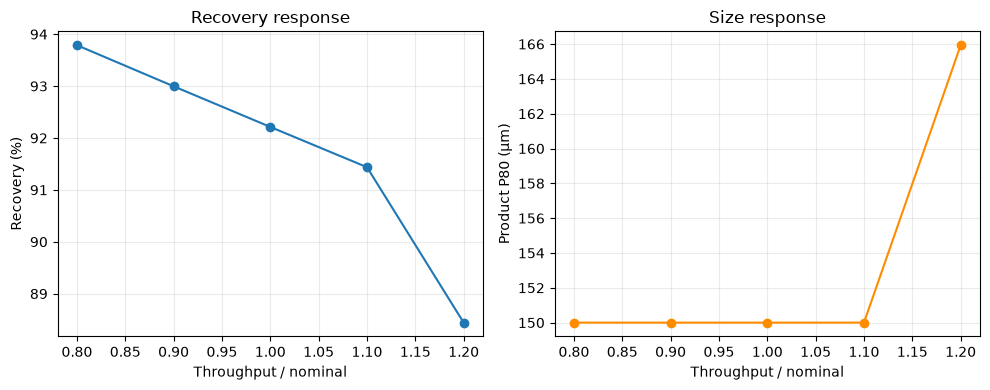

In [11]:
# Plot responses from the independently solved operating points.
import matplotlib.pyplot as plt

factors = [0.8, 0.9, 1.0, 1.1, 1.2]
runs = [response_0_8, response_0_9, response_1_0, response_1_1, response_1_2]
rates = [run.metrics["recovery_pct"] for run in runs]
sizes = [run.metrics["p80_um"] for run in runs]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(factors, rates, marker="o")
axes[0].set(xlabel="Throughput / nominal", ylabel="Recovery (%)", title="Recovery response")
axes[1].plot(factors, sizes, marker="o", color="darkorange")
axes[1].set(xlabel="Throughput / nominal", ylabel="Product P80 (µm)", title="Size response")
for axis in axes:
    axis.grid(True, alpha=0.25)
fig.tight_layout()


Figure 27 in the level 2 01 comminution lesson reports outputs of independently solved operating points. For figure 27 in level 2 01 comminution, each mark is a separate model evaluation at its stated setting. For figure 27 in level 2 01 comminution, check recovery, size and energy against the contract limits. The line in figure 27 only guides comparison.

At level 2 in 01 comminution, interpretation 1 is that comminution couples breakage, classification and recycle. At level 2 in 01 comminution, interpretation 2 is that a change in fresh feed can move the mill toward its installed-power limit, alter the size distribution entering the classifier and change circulating load. At level 2 in 01 comminution, interpretation 3 is that p80 alone does not describe the full distribution, so inspect the plotted cumulative curves and the engine's per-stream audit together. At level 2 in 01 comminution, interpretation 4 is that the Bond work-index equation is an empirical standard-circuit relation with a specified feed and product size basis. At level 2 in 01 comminution, interpretation 5 is that it is not a mechanistic law for every particle. At level 2 in 01 comminution, interpretation 6 is that rittinger and Kick express different scaling assumptions and should be compared at a common calibration point. At level 2 in 01 comminution, interpretation 7 is that a closed mass balance is necessary for a credible calculation, but it cannot establish that the breakage or selection parameters represent an operating plant. At level 2 in 01 comminution, interpretation 8 is that an independent validation would require measured feed and product size distributions, throughput, power and ore-specific calibration, with an agreed sampling protocol. At level 2 in 01 comminution, extension 1 shows that a useful validation table would align paired feed and product size classes with mill power and circulating load, because matching one percentile can hide a distribution error. At level 2 in 01 comminution, extension 2 shows that report the basis for moisture, density and work-index measurements, and state whether size values are mass or volume fractions. At level 2 in 01 comminution, extension 3 shows that the current circuit calculation is steady state, so a time sequence in the interface is a control sweep rather than a transient population balance.

## Results

**Answer:** In this level 2 01 comminution lesson, the executed circuit reports recovery of 93.788 percent at the first controlled throughput setting for Reconstruct the energy and recycle calculation.

The classifier curve reports per-class routing, and the energy table distinguishes the circuit's net grinding energy from standard Bond requirement. Rittinger and Kick are alternative calibrated comparisons; adding them to Bond would double-count energy. The sensitivity plot holds feed and work index fixed and is not an operating recommendation.

## Summary

You traced classifier partition, recycle load and energy outputs through the implemented engine. The circuit is steady state; these equations do not represent breakage dynamics over real time, and the nominal plant is an authored scenario.

## References

- https://www.globalminingguidelines.org/guidelines/bond-efficiency/
- https://doi.org/10.1016/0301-7516(80)90034-4
- https://doi.org/10.1016/0301-7516(80)90034-4